In [2]:
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import r2_score


KNN (K-Nearest Neighbors) es un algoritmo de aprendizaje supervisado usado para clasificación y regresión. Su principio es simple: predice un valor o categoría basado en los K vecinos más cercanos en el espacio de características.


1- Se elige un número  K de vecinos (hiperparámetro).

2- Para una nueva observación, se calculan las distancias con todos los datos de entrenamiento.

3- Se seleccionan los  K vecinos más cercanos. 

4- Se predice el promedio de los valores de los K vecinos.


## Para determinar los vecinos más cercanos

### Definición General
La distancia euclidiana entre dos puntos \( A \) y \( B \) en un espacio \( n \)-dimensional se define como:

$$
d(A, B) = \sqrt{\sum_{i=1}^{n} (x_i^A - x_i^B)^2}
$$

#### Casos Específicos

### Caso en Dos Dimensiones
En un espacio bidimensional (\( n = 2 \)):

$$
d(A, B) = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}
$$

### Caso en Tres Dimensiones
En un espacio tridimensional (\( n = 3 \)):

$$
d(A, B) = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2 + (z_2 - z_1)^2}
$$

**Ejemplo Numérico:**
Si tenemos los puntos \( A(1,2,3) \) y \( B(4,6,8) \), la distancia euclidiana es:

$$
d(A, B) = \sqrt{(4 - 1)^2 + (6 - 2)^2 + (8 - 3)^2} = \sqrt{9 + 16 + 25} = \sqrt{50} \approx 7.07
$$



In [3]:
### Ejemplo distancie uclidiana

In [4]:
df = pd.read_csv(r"C:\Users\carla\OneDrive\Documentos\analisis de datos\CSVS\housing.csv")
df = pd.get_dummies(df)
df['total_bedrooms'] = df['total_bedrooms'].fillna(df.total_bedrooms.mean())

### Crea el modelo KNN y realiza cross validation manual 

In [5]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


# Normalizar las características (KNN es sensible a escalas)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [6]:
X_standarizado= StandardScaler().fit_transform(X)

X_train_standarizado=StandardScaler().fit_transform(X_train)
X_test_standarizado=StandardScaler().fit_transform(X_test)


In [7]:
r2=[]
ks=np.arange(1,59)
for i in ks:
    model=KNeighborsRegressor(n_neighbors=i)
    model.fit(X_train_standarizado, y_train)
    predicciones= model.predict(X_test_standarizado)
    r2_model= r2_score(y_pred=predicciones, y_true=y_test)
    r2.append(r2_model)

In [8]:
import matplotlib.pyplot as plt

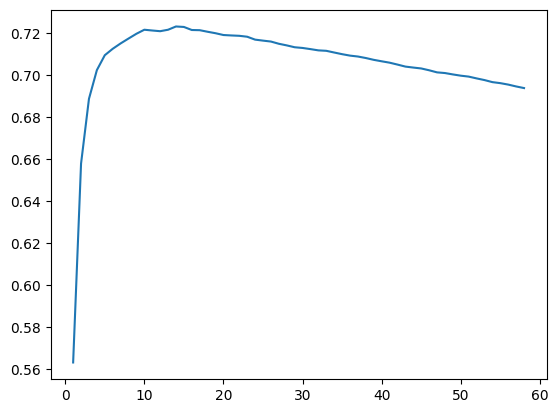

In [9]:
plt.plot(ks,r2)

In [10]:
pipeline= Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])
params={"model__n_neighbors": np.arange(1,59)}
grid=GridSearchCV(estimator=pipeline, cv=5, scoring="r2",param_grid=params)
grid.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': array([ 1, 2..., 56, 57, 58])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

In [11]:
grid.best_params_
r2_score(y_true=y_test,y_pred=predicciones)

0.6936964159261109

In [12]:
## Grafica los resultados

In [13]:
df_predicciones= pd.DataFrame({
    "real": y_test,
    "predicciones": predicciones
})

In [14]:
df_predicciones["bins"]= pd.qcut(df_predicciones["predicciones"], q=10, labels=False)

In [15]:
bivariate= df_predicciones.groupby("bins").mean()

In [16]:
bivariate

,real,predicciones
bins,,
0,74436.775806,81045.313793
1,110363.812601,111649.736004
2,135024.235864,135745.048382
3,158723.589661,160363.372068
4,177950.730210,184400.126650
5,202537.806139,205103.857417
6,230178.216478,229685.063785
7,260434.856452,257155.617102
8,309101.996764,292162.438902


In [17]:
## Ahora grid search, comparalo contra una lineal y polinomial 

C:\Users\carla\AppData\Local\Temp\ipykernel_22476\3790606934.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


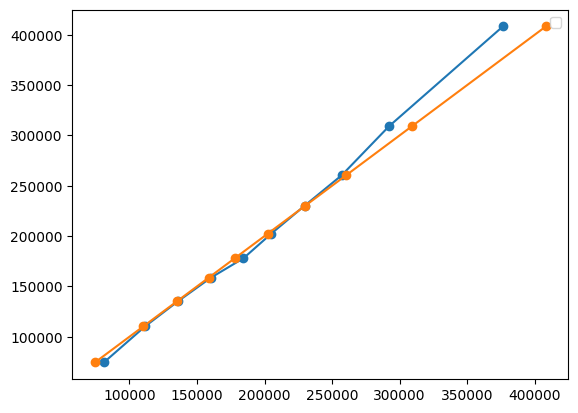

In [18]:
plt.plot(bivariate.predicciones, bivariate.real, marker="o")
plt.plot(bivariate.real, bivariate.real, marker="o")
plt.legend()